In [1]:
%pip install -e "C:/Users/yqi/SAI/watts"

Obtaining file:///C:/Users/yqi/SAI/watts
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Checking if build backend supports build_editable: started
  Checking if build backend supports build_editable: finished with status 'done'
  Getting requirements to build editable: started
  Getting requirements to build editable: finished with status 'done'
  Preparing editable metadata (pyproject.toml): started
  Preparing editable metadata (pyproject.toml): finished with status 'done'
  Building editable for watts (pyproject.toml): started
  Building editable for watts (pyproject.toml): finished with status 'done'
  Created wheel for watts: filename=watts-0.5.2.dev0-py3-none-any.whl size=3513 sha256=355fc2b3d331e98a775bee446c0dcafbf4066d10c05b295b932729febaa81f7e
  Stored in directory: C:\Users\yqi\AppData\Local\Temp\pip-ephem-wheel-cache-_wcq4a6y\wheels\3f\df\61\f648eb1e5991a4da7914a67e3e56f1896450d9de75676413e4
Successfully built watts
 

DEPRECATION: Loading egg at c:\users\yqi\appdata\local\anaconda3\lib\site-packages\pyclus-0.1-py3.11.egg is deprecated. pip 23.3 will enforce this behaviour change. A possible replacement is to use pip for package installation..
DEPRECATION: Loading egg at c:\users\yqi\appdata\local\anaconda3\lib\site-packages\saitools-0.1-py3.11.egg is deprecated. pip 23.3 will enforce this behaviour change. A possible replacement is to use pip for package installation..


In [2]:
import matplotlib.pyplot as plt
import numpy as np

from watts.parameters import Parameters
from watts.plugin_cyclus import ResultsCyclus
from watts.results import ExecInfo
from watts.enr_utils import enrichment_cascade


In [3]:
inputs = []
outputs = ['./nuc46_nz50_ot2.sqlite']

obj = ResultsCyclus(Parameters(), ExecInfo(1, 'cyclus', 'name', 1),
                    inputs, outputs)

In [4]:
r = obj.obj.cur.execute('SELECT distinct(commodity) FROM transactions')

In [5]:
[x['commodity'] for x in r]

['natl_u',
 'uox',
 'tailss',
 'uox_waste',
 'ap1000_uox',
 'triso',
 'smr_uox',
 'triso_unf',
 'natrium_fuel',
 'uox_waste_voygr',
 'uox_waste_ap1000',
 'natrium_waste']

In [6]:
reactors = obj.reactors
reactors

{604: 'NINE MILE POINT-1',
 605: 'DRESDEN-2',
 606: 'GINNA',
 607: 'POINT BEACH-1',
 608: 'ROBINSON-2',
 609: 'MONTICELLO',
 610: 'DRESDEN-3',
 611: 'PALISADES',
 612: 'POINT BEACH-2',
 613: 'TURKEY POINT-3',
 614: 'SURRY-1',
 615: 'QUAD CITIES-1',
 616: 'QUAD CITIES-2',
 617: 'SURRY-2',
 618: 'OCONEE-1',
 619: 'TURKEY POINT-4',
 620: 'PRAIRIE ISLAND-1',
 621: 'PEACH BOTTOM-2',
 622: 'COOPER',
 623: 'BROWNS FERRY-1',
 624: 'OCONEE-2',
 625: 'OCONEE-3',
 626: 'PEACH BOTTOM-3',
 627: 'ANO-1',
 628: 'PRAIRIE ISLAND-2',
 629: 'BROWNS FERRY-2',
 630: 'CALVERT CLIFFS-1',
 631: 'FITZPATRICK',
 632: 'COOK-1',
 633: 'BRUNSWICK-2',
 634: 'HATCH-1',
 635: 'MILLSTONE-2',
 636: 'INDIAN POINT-3',
 637: 'BEAVER VALLEY-1',
 638: 'ST. LUCIE-1',
 639: 'BROWNS FERRY-3',
 640: 'BRUNSWICK-1',
 641: 'CALVERT CLIFFS-2',
 642: 'SALEM-1',
 643: 'FARLEY-1',
 644: 'NORTH ANNA-1',
 645: 'COOK-2',
 646: 'DAVIS BESSE-1',
 647: 'HATCH-2',
 648: 'ANO-2',
 649: 'NORTH ANNA-2',
 650: 'SEQUOYAH-1',
 651: 'FARLEY-2',
 65

In [7]:
named_reactors = ['AP1000', 'VOYGR', '12VOYGR' 'Natrium', 'XE100', '4XE100']

In [8]:
legacy_protos = [q for q in obj.reactors.values() if q not in named_reactors]
np.array(legacy_protos)

array(['NINE MILE POINT-1', 'DRESDEN-2', 'GINNA', 'POINT BEACH-1',
       'ROBINSON-2', 'MONTICELLO', 'DRESDEN-3', 'PALISADES',
       'POINT BEACH-2', 'TURKEY POINT-3', 'SURRY-1', 'QUAD CITIES-1',
       'QUAD CITIES-2', 'SURRY-2', 'OCONEE-1', 'TURKEY POINT-4',
       'PRAIRIE ISLAND-1', 'PEACH BOTTOM-2', 'COOPER', 'BROWNS FERRY-1',
       'OCONEE-2', 'OCONEE-3', 'PEACH BOTTOM-3', 'ANO-1',
       'PRAIRIE ISLAND-2', 'BROWNS FERRY-2', 'CALVERT CLIFFS-1',
       'FITZPATRICK', 'COOK-1', 'BRUNSWICK-2', 'HATCH-1', 'MILLSTONE-2',
       'INDIAN POINT-3', 'BEAVER VALLEY-1', 'ST. LUCIE-1',
       'BROWNS FERRY-3', 'BRUNSWICK-1', 'CALVERT CLIFFS-2', 'SALEM-1',
       'FARLEY-1', 'NORTH ANNA-1', 'COOK-2', 'DAVIS BESSE-1', 'HATCH-2',
       'ANO-2', 'NORTH ANNA-2', 'SEQUOYAH-1', 'FARLEY-2', 'SALEM-2',
       'MCGUIRE-1', 'SEQUOYAH-2', 'SUSQUEHANNA-1', 'ST. LUCIE-2',
       'SUMMER-1', 'LASALLE-1', 'MCGUIRE-2', 'LASALLE-2', 'COLUMBIA',
       'CALLAWAY-1', 'SUSQUEHANNA-2', 'DIABLO CANYON-1', 'CA

In [9]:
def aggregate_smr(d):
    # 4XE100 is 4 XE100s at once and 12VOYGR is 12 VOYGRs at once 
    # because we can't have that many agents deployed
    if '12VOYGR' in d:
        if 'VOYGR' in d:
            d['VOYGR'] += d.pop('12VOYGR')
        else:
            d['VOYGR'] = d.pop('12VOYGR')
    if '4XE100' in d:
        if 'XE100' in d:
            d['XE100'] += d.pop('4XE100')
        else:
            d['XE100'] = d.pop('4XE100')
    return d

In [10]:
data_dict = {}

In [11]:
which = 'natu'
natural_assay = 0.00711
tails_assay = 0.0025
data_dict[which] = {}
for proto in named_reactors:
    if proto in reactors.values():
        data_dict[which][proto] = obj.obj.stock_fuel_natu(proto, natural_assay, tails_assay)

data_dict[which]['legacy'] = obj.obj.stock_fuel_natu(legacy_protos, natural_assay, tails_assay)
data_dict[which] = aggregate_smr(data_dict[which])
years = obj.time_dict['years'][::12] # Time is month by month


AssertionError: Varible prod needs to be a single number.

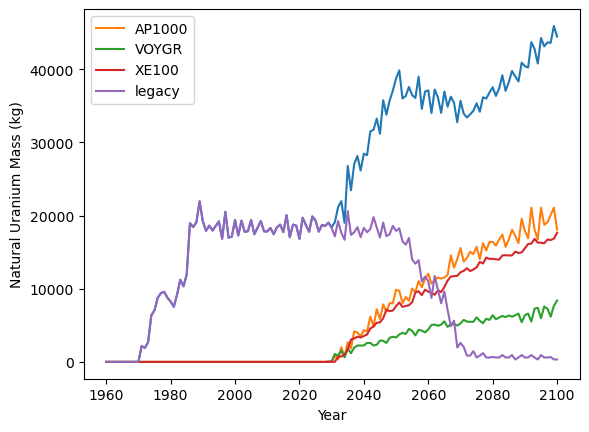

In [ ]:
plt.plot(years, sum(data_dict[which].values())/1e3)
for k,v in data_dict[which].items():
    plt.plot(years, v/1e3, label=k)
plt.xlabel("Year")
plt.ylabel("Natural Uranium Mass (kg)")
plt.legend()

In [ ]:
which = 'swu'
data_dict[which] = {}
for proto in named_reactors:
    if proto in reactors.values():
        data_dict[which][proto] =  obj.obj.stock_fuel_swu(proto, natural_assay, tails_assay)

data_dict[which]['legacy'] = obj.obj.stock_fuel_swu(legacy_protos, natural_assay, tails_assay)

data_dict[which] = aggregate_smr(data_dict[which])



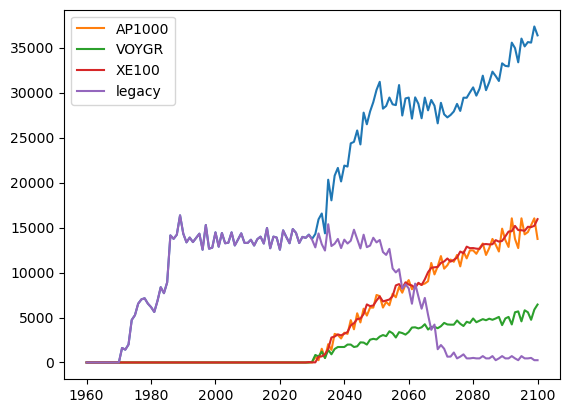

In [ ]:
plt.plot(years, sum(data_dict[which].values())/1e3)
for k,v in data_dict[which].items():
    plt.plot(years, v/1e3, label=k)
plt.legend()

In [ ]:
# get fuel demand
which = 'fuel'
data_dict[which] = {}
for proto in named_reactors:
    if proto in reactors.values():
        data_dict[which][proto] = obj.obj.process_prototype(proto, False)[1]['receiving']
        data_dict[which][proto] = list(data_dict[which][proto].values())[0]

data_dict[which]['legacy'] = sum(obj.obj.process_prototype(legacy_protos, False)[1]['receiving'].values())
data_dict[which] = aggregate_smr(data_dict[which])

	Processing prototype: AP1000
	Processing prototype: VOYGR
	Processing prototype: XE100
	Processing prototype: 4XE100
	Processing prototype: ['NINE MILE POINT-1', 'DRESDEN-2', 'GINNA', 'POINT BEACH-1', 'ROBINSON-2', 'MONTICELLO', 'DRESDEN-3', 'PALISADES', 'POINT BEACH-2', 'TURKEY POINT-3', 'SURRY-1', 'QUAD CITIES-1', 'QUAD CITIES-2', 'SURRY-2', 'OCONEE-1', 'TURKEY POINT-4', 'PRAIRIE ISLAND-1', 'PEACH BOTTOM-2', 'COOPER', 'BROWNS FERRY-1', 'OCONEE-2', 'OCONEE-3', 'PEACH BOTTOM-3', 'ANO-1', 'PRAIRIE ISLAND-2', 'BROWNS FERRY-2', 'CALVERT CLIFFS-1', 'FITZPATRICK', 'COOK-1', 'BRUNSWICK-2', 'HATCH-1', 'MILLSTONE-2', 'INDIAN POINT-3', 'BEAVER VALLEY-1', 'ST. LUCIE-1', 'BROWNS FERRY-3', 'BRUNSWICK-1', 'CALVERT CLIFFS-2', 'SALEM-1', 'FARLEY-1', 'NORTH ANNA-1', 'COOK-2', 'DAVIS BESSE-1', 'HATCH-2', 'ANO-2', 'NORTH ANNA-2', 'SEQUOYAH-1', 'FARLEY-2', 'SALEM-2', 'MCGUIRE-1', 'SEQUOYAH-2', 'SUSQUEHANNA-1', 'ST. LUCIE-2', 'SUMMER-1', 'LASALLE-1', 'MCGUIRE-2', 'LASALLE-2', 'COLUMBIA', 'CALLAWAY-1', 'S

In [ ]:
enr = 18e-2
swu = np.array(enrichment_cascade(natural_assay, enr, tails_assay)['swu'])
swu

array([34.32527047,  2.65985151,  0.        ])

In [ ]:
xx = data_dict['fuel']['AP1000'] * swu[:, None]

In [ ]:
xx[0,:]

array([       0.        ,        0.        ,        0.        ,
              0.        ,        0.        ,        0.        ,
              0.        ,        0.        ,        0.        ,
              0.        ,        0.        ,        0.        ,
              0.        ,        0.        ,        0.        ,
              0.        ,        0.        ,        0.        ,
              0.        ,        0.        ,        0.        ,
              0.        ,        0.        ,        0.        ,
              0.        ,        0.        ,        0.        ,
              0.        ,        0.        ,        0.        ,
              0.        ,        0.        ,        0.        ,
              0.        ,        0.        ,        0.        ,
              0.        ,        0.        ,        0.        ,
              0.        ,        0.        ,        0.        ,
              0.        ,        0.        ,        0.        ,
              0.        ,        0.     

In [ ]:
test = obj.obj.process_prototype(['VOGTLE-3', 'VOGTLE-4'],
                          False)[1]['receiving']

	Processing prototype: ['VOGTLE-3', 'VOGTLE-4']


In [ ]:
# treating vogtle as not legacy
test['ap1000_uox'] + data_dict['fuel']['AP1000']

array([      0.,       0.,       0.,       0.,       0.,       0.,
             0.,       0.,       0.,       0.,       0.,       0.,
             0.,       0.,       0.,       0.,       0.,       0.,
             0.,       0.,       0.,       0.,       0.,       0.,
             0.,       0.,       0.,       0.,       0.,       0.,
             0.,       0.,       0.,       0.,       0.,       0.,
             0.,       0.,       0.,       0.,       0.,       0.,
             0.,       0.,       0.,       0.,       0.,       0.,
             0.,       0.,       0.,       0.,       0.,       0.,
             0.,       0.,       0.,       0.,       0.,       0.,
             0.,       0.,       0.,       0.,   84775.,  118685.,
         67820.,   33910.,   33910.,   67820.,   33910.,  118685.,
        101730.,  237370.,  101730.,  339100.,  220415.,  457785.,
        474740.,  389965.,  474740.,  491695.,  661245.,  525605.,
        796885.,  627335.,  830795.,  762975.,  847750.,  8477

In [ ]:
data_dict['fuel']['AP1000']

array([      0.,       0.,       0.,       0.,       0.,       0.,
             0.,       0.,       0.,       0.,       0.,       0.,
             0.,       0.,       0.,       0.,       0.,       0.,
             0.,       0.,       0.,       0.,       0.,       0.,
             0.,       0.,       0.,       0.,       0.,       0.,
             0.,       0.,       0.,       0.,       0.,       0.,
             0.,       0.,       0.,       0.,       0.,       0.,
             0.,       0.,       0.,       0.,       0.,       0.,
             0.,       0.,       0.,       0.,       0.,       0.,
             0.,       0.,       0.,       0.,       0.,       0.,
             0.,       0.,       0.,       0.,       0.,       0.,
             0.,       0.,       0.,       0.,       0.,   84775.,
         33910.,  203460.,   67820.,  271280.,  186505.,  423875.,
        406920.,  356055.,  440830.,  423875.,  627335.,  491695.,
        729065.,  593425.,  796885.,  695155.,  813840.,  8138

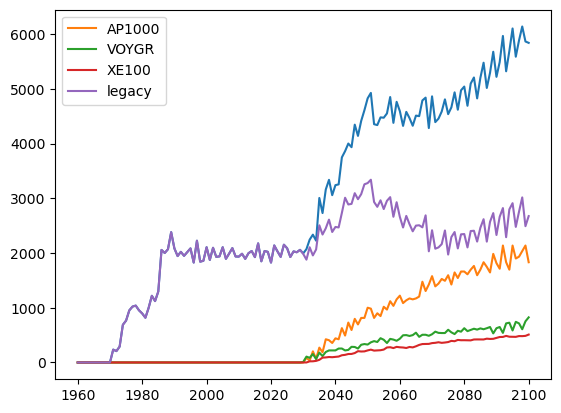

In [ ]:
import matplotlib.pyplot as plt
plt.plot(years, sum(data_dict[which].values())/1e3)
for k,v in data_dict[which].items():
    plt.plot(years, v/1e3, label=k)
plt.legend()